# 07 — Regression Diagnostics and Robustness

I check the preferred Model 3 from Notebook 06, keeping its seven predictors and 4,016-space sample unchanged. I examine residuals, variance and functional form, then compare influence sensitivity and a 1,000-replication bootstrap. The full-sample OLS model remains the primary specification throughout.

I reviewed `project1-1.pdf`, `Regression_Lecture0.ipynb`, `Regression_Lecture1.ipynb`, `Regression_Lecture2.ipynb`, their available numbered copies, and `Case_1_430_Lab.ipynb` in Downloads, together with Notebooks 01 and 04–06. Lecture 1 supplies residual/normality plots and leverage screens; Lecture 2 supplies variance tests, RESET, influence plots, HC1 standard errors, and bootstrap examples. Methods not found in those materials are identified below rather than added silently.

## 1. Load the data and reproduce Notebook 06

I apply the same FLAT + TOD restriction and complete-case variable list as Notebook 06. Income is included only in the sample restriction to match Notebook 05, not as a predictor in any of the three models. I preserve the original row index so diagnostics can be linked back to the correct SpaceID and BlockFace.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset

%matplotlib inline

parking = pd.read_csv(
    "../data/processed/parking_cross_section.csv",
    dtype={"SpaceID": str, "GEOID": str}
)
print("Original observations:", len(parking))

parking = parking[parking["RateType"].isin(["FLAT", "TOD"])].copy()
parking["RateType_TOD"] = (parking["RateType"] == "TOD").astype(int)
print("FLAT + TOD observations:", len(parking))

Original observations: 4139
FLAT + TOD observations: 4060


In [2]:
variables = [
    "occupancy_rate", "price_midpoint", "time_limit_hours",
    "population_density", "nearby_restaurant_retail_count",
    "drive_alone_share", "transit_share", "RateType_TOD", "median_income"
]
print("Missing values before the common-sample restriction:")
print(parking[variables].isnull().sum())

data = parking[variables].dropna().copy()
y = data["occupancy_rate"]
print("Comparison observations:", len(data))
print("Unique SpaceIDs:", parking.loc[data.index, "SpaceID"].nunique())
print("Duplicate SpaceIDs:", parking.loc[data.index, "SpaceID"].duplicated().sum())
print("Census tracts:", parking.loc[data.index, "GEOID"].nunique())

Missing values before the common-sample restriction:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
nearby_restaurant_retail_count     0
drive_alone_share                  0
transit_share                      0
RateType_TOD                       0
median_income                     44
dtype: int64
Comparison observations: 4016
Unique SpaceIDs: 4016
Duplicate SpaceIDs: 0
Census tracts: 45


In [3]:
X1 = sm.add_constant(data[["price_midpoint"]])
model1 = sm.OLS(y, X1).fit()

X2 = sm.add_constant(data[[
    "price_midpoint", "time_limit_hours", "population_density",
    "nearby_restaurant_retail_count"
]])
model2 = sm.OLS(y, X2).fit()

In [4]:
predictors = [
    "price_midpoint", "time_limit_hours", "population_density",
    "nearby_restaurant_retail_count", "drive_alone_share",
    "transit_share", "RateType_TOD"
]
X3 = sm.add_constant(data[predictors])
model3 = sm.OLS(y, X3).fit()

model_check = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "N": [int(model1.nobs), int(model2.nobs), int(model3.nobs)],
    "Adjusted R2": [model1.rsquared_adj, model2.rsquared_adj, model3.rsquared_adj],
    "AIC": [model1.aic, model2.aic, model3.aic],
    "BIC": [model1.bic, model2.bic, model3.bic]
})
model_check.round(5)

,Model,N,Adjusted R2,AIC,BIC
0,Model 1,4016,0.15657,-2483.67051,-2471.07443
1,Model 2,4016,0.24303,-2915.05190,-2883.56169
2,Model 3,4016,0.27235,-3070.71241,-3020.32808


In [5]:
coefficient_check = pd.DataFrame({
    "Model 1": model1.params,
    "Model 2": model2.params,
    "Model 3": model3.params
})
coefficient_check.style.format("{:.6g}", na_rep="—")

,Model 1,Model 2,Model 3
RateType_TOD,—,—,0.0330042
const,0.42375,0.382602,0.456337
drive_alone_share,—,—,-0.198101
nearby_restaurant_retail_count,—,-0.000229516,-0.000321282
population_density,—,4.0583e-06,4.57052e-06
price_midpoint,0.0545148,0.0606406,0.0556328
time_limit_hours,—,0.00364837,0.00487929
transit_share,—,—,0.0196471


All three models reproduce Notebook 06 on 4,016 unique spaces in 45 tracts. Their adjusted R² values are 0.15657, 0.24303, and 0.27235; AIC values are −2,483.67, −2,915.05, and −3,070.71, with matching coefficients and BIC values. Notebook 06 provisionally preferred Model 3 on fit and validation criteria, so the detailed checks below focus on that model.

## 2. Inspect the residual plots

I calculate fitted occupancy, residuals, and internally standardized residuals using the lecture approach. I plot residuals against fitted occupancy, price, and population density to look for changing spread or systematic patterns. The histogram gives a first view of the residual distribution without deleting unusual observations.

In [6]:
fitted = model3.fittedvalues
residuals = model3.resid
influence = model3.get_influence()
standardized = influence.resid_studentized_internal

print("Fitted occupancy outside [0, 1]:", (~fitted.between(0, 1)).sum())
residuals.describe()

Fitted occupancy outside [0, 1]: 4


count    4.016000e+03
mean    -3.244116e-13
std      1.647846e-01
min     -6.240984e-01
25%     -1.125996e-01
50%     -6.126102e-04
75%      1.102839e-01
max      5.685229e-01
dtype: float64

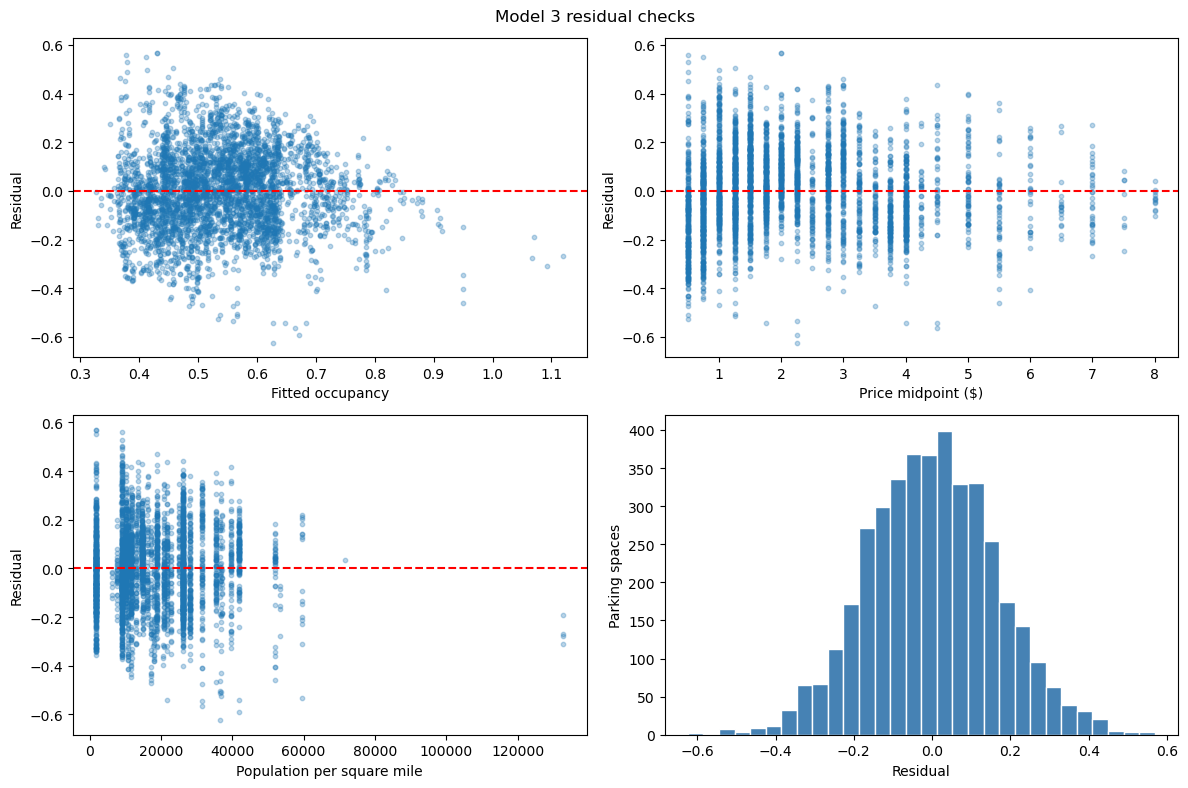

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].scatter(fitted, residuals, s=10, alpha=0.3)
axes[0, 0].set_xlabel("Fitted occupancy")
axes[0, 1].scatter(data["price_midpoint"], residuals, s=10, alpha=0.3)
axes[0, 1].set_xlabel("Price midpoint ($)")
axes[1, 0].scatter(data["population_density"], residuals, s=10, alpha=0.3)
axes[1, 0].set_xlabel("Population per square mile")

axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_ylabel("Residual")
axes[0, 1].set_ylabel("Residual")
axes[1, 0].set_ylabel("Residual")
axes[1, 1].hist(residuals, bins=30, color="steelblue", edgecolor="white")
axes[1, 1].set_xlabel("Residual")
axes[1, 1].set_ylabel("Parking spaces")
fig.suptitle("Model 3 residual checks")
fig.tight_layout()
plt.show()

Residuals are centered near zero overall but range from about −0.624 to 0.569. The spread is not uniform across fitted values, and shared tract measurements create vertical bands in the density plot. Four fitted values exceed one, which is another limitation of using an unconstrained linear model for a bounded outcome. These plots motivate the formal tests below; I do not clip predictions or alter the model.

## 3. Check residual normality

I compare internally standardized residuals with normal quantiles and use the Jarque–Bera test, whose null is normal residuals. The histogram is shown in the preceding section rather than repeated here. With a large sample, a test can detect small departures, and failing to reject is not proof of normality.

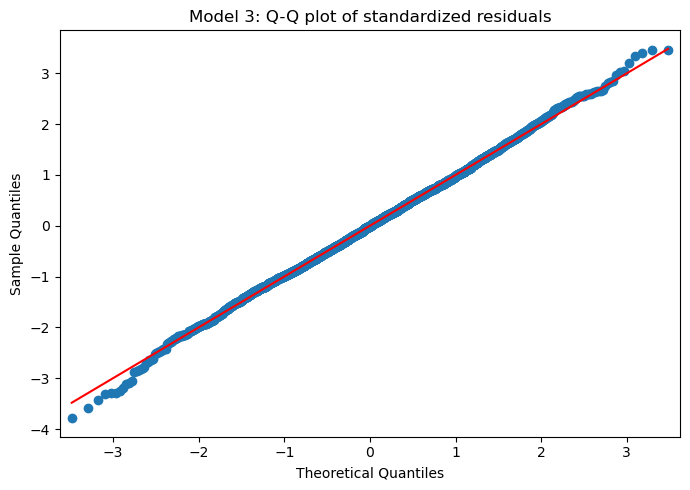

JB statistic    3.835976
P-value         0.146902
Skewness        0.031068
Kurtosis        3.138070
dtype: float64

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sm.qqplot(standardized, line="s", ax=ax)
ax.set_title("Model 3: Q-Q plot of standardized residuals")
fig.tight_layout()
plt.show()

jb = jarque_bera(residuals)
normality = pd.Series(jb, index=["JB statistic", "P-value", "Skewness", "Kurtosis"])
normality

Jarque–Bera is **3.836**, with **p = 0.1469**, so I do not reject residual normality at 5%. Skewness is close to zero and kurtosis is about 3.138; the Q-Q plot is close to the reference line in the center with some tail departures. This result says nothing by itself about constant variance, independence, or the correctness of the conditional mean.

## 4. Check constant variance and compare robust uncertainty

I use the lecture's scale-location plot, Breusch–Pagan test, and White test. Both tests have a null of constant error variance; I report their LM and F versions without treating them as separate independent checks. The scale-location plot uses the square root of absolute internally standardized residuals.

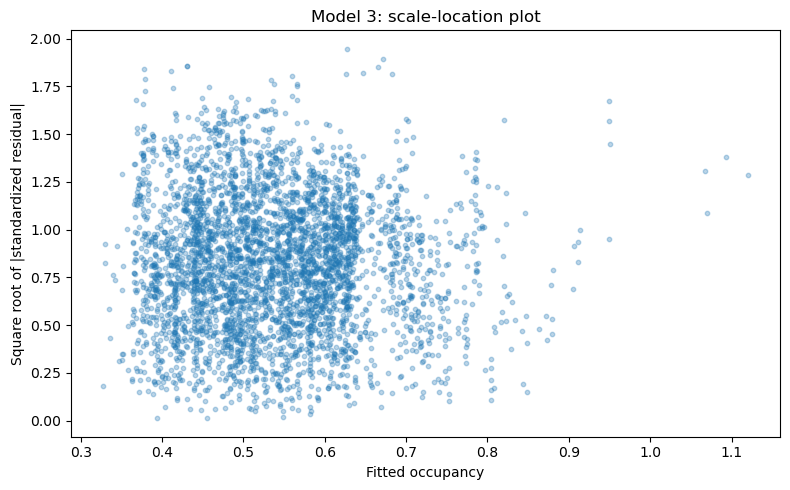

,Test,LM statistic,LM p-value,F statistic,F p-value
0,Breusch–Pagan (default Koenker version),207.230,3.374e-41,31.153,2.605e-42
1,White,394.973,4.755e-63,12.772,8.185e-67


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted, np.sqrt(np.abs(standardized)), s=10, alpha=0.3)
ax.set_xlabel("Fitted occupancy")
ax.set_ylabel("Square root of |standardized residual|")
ax.set_title("Model 3: scale-location plot")
fig.tight_layout()
plt.show()

bp = het_breuschpagan(residuals, X3)
white = het_white(residuals, X3)
variance_tests = pd.DataFrame({
    "Test": ["Breusch–Pagan (default Koenker version)", "White"],
    "LM statistic": [bp[0], white[0]],
    "LM p-value": [bp[1], white[1]],
    "F statistic": [bp[2], white[2]],
    "F p-value": [bp[3], white[3]]
})
variance_tests.style.format({
    "LM statistic": "{:.3f}", "LM p-value": "{:.3e}",
    "F statistic": "{:.3f}", "F p-value": "{:.3e}"
})

Both tests reject constant variance: the Breusch–Pagan LM p-value is **3.37 × 10⁻⁴¹**, and White's is **4.75 × 10⁻⁶³**. Conventional standard errors, intervals, and tests therefore need caution; changing the covariance estimate does not change the OLS coefficients or fix a misspecified mean.

Lecture 2 mentions the HC0–HC3 family, but its worked comparisons use **HC1**, not HC3. I follow that demonstrated HC1 code below rather than claim to have a worked HC3 example. This comparison still treats different spaces as independent.

In [10]:
model3_hc1 = sm.OLS(y, X3).fit(cov_type="HC1")

robust_comparison = pd.DataFrame({
    "Coefficient": model3.params,
    "OLS SE": model3.bse,
    "HC1 SE": model3_hc1.bse,
    "OLS p-value": model3.pvalues,
    "HC1 p-value": model3_hc1.pvalues,
    "HC1 95% lower": model3_hc1.conf_int()[0],
    "HC1 95% upper": model3_hc1.conf_int()[1]
})
print("Largest coefficient change:", (model3.params - model3_hc1.params).abs().max())
robust_comparison.style.format({
    "Coefficient": "{:.6g}", "OLS SE": "{:.6g}", "HC1 SE": "{:.6g}",
    "OLS p-value": "{:.3e}", "HC1 p-value": "{:.3e}",
    "HC1 95% lower": "{:.6g}", "HC1 95% upper": "{:.6g}"
})

Largest coefficient change: 0.0


,Coefficient,OLS SE,HC1 SE,OLS p-value,HC1 p-value,HC1 95% lower,HC1 95% upper
const,0.456337,0.0157939,0.0171155,6.470e-167,1.291e-156,0.422792,0.489883
price_midpoint,0.0556328,0.00236136,0.00232226,4.731e-115,7.931e-127,0.0510813,0.0601844
time_limit_hours,0.00487929,0.00294796,0.00313717,9.797e-02,1.199e-01,-0.00126946,0.011028
population_density,4.57052e-06,2.21771e-07,2.37074e-07,8.803e-90,8.077e-83,4.10586e-06,5.03518e-06
nearby_restaurant_retail_count,-0.000321282,2.29852e-05,2.4298e-05,2.189e-43,6.502e-40,-0.000368905,-0.000273659
drive_alone_share,-0.198101,0.0208314,0.0211007,3.195e-21,6.095e-21,-0.239458,-0.156744
transit_share,0.0196471,0.0468362,0.0452127,6.749e-01,6.639e-01,-0.0689682,0.108262
RateType_TOD,0.0330042,0.00731608,0.00857071,6.631e-06,1.177e-04,0.0162059,0.0498025


The price estimate stays **0.05563**; its HC1 standard error is **0.002322**, versus **0.002361** conventionally, with an HC1 95% interval of **0.05108 to 0.06018**. Its positive association remains statistically clear under this correction, while time limit and transit share remain uncertain. HC1 uses statsmodels' default normal-reference inference here; it does not account for within-tract dependence.

## 5. Check the linear functional form

I use the lecture's Ramsey RESET approach, adding the square of fitted values in an auxiliary test. The null is that this added term is unnecessary. A rejection points to a possible specification problem, not to the particular variable or transformation that would fix it.

In [11]:
reset = linear_reset(model3, power=2, test_type="fitted", use_f=True)
print(reset)

<F test: F=122.0777512836214, p=5.604940901584903e-28, df_denom=4.01e+03, df_num=1>


RESET gives **F = 122.078** and **p = 5.60 × 10⁻²⁸**, suggesting a problem with the current linear specification. Because this is the conventional test and heteroskedasticity is present, I read it alongside the plots rather than treating it as an isolated diagnosis. Simple logs of positive density or business counts could be considered later, but I do not change the predictors or outcome here.

## 6. Screen for influential observations

I link Cook's distance, leverage, and externally studentized residuals back to the unchanged source-row index and parking identifiers. I use the requested Cook's rule **4/n**, plus Lecture 1's **2p/n** leverage rule and **|studentized residual| > 2**, where p includes the intercept. These are screening rules, not evidence that a record is incorrect; the 4/n cutoff is supplied in the project instructions rather than shown as a worked lecture cutoff.

In [12]:
diagnostics = parking.loc[data.index, ["SpaceID", "BlockFace", "GEOID"]].copy()
diagnostics["cooks_d"] = influence.cooks_distance[0]
diagnostics["hat_diag"] = influence.hat_matrix_diag
diagnostics["studentized_residual"] = influence.resid_studentized_external

n = int(model3.nobs)
p = len(model3.params)
cook_cutoff = 4 / n
leverage_cutoff = 2 * p / n

diagnostics["cook_flag"] = diagnostics["cooks_d"] > cook_cutoff
diagnostics["leverage_flag"] = diagnostics["hat_diag"] > leverage_cutoff
diagnostics["residual_flag"] = diagnostics["studentized_residual"].abs() > 2

print("Rows align with the model:", diagnostics.index.equals(model3.model.data.row_labels))
print("n, p (including intercept):", n, p)
print("Cook cutoff:", cook_cutoff)
print("Leverage cutoff:", leverage_cutoff)
diagnostics[["cook_flag", "leverage_flag", "residual_flag"]].sum()

Rows align with the model: True
n, p (including intercept): 4016 8
Cook cutoff: 0.00099601593625498
Leverage cutoff: 0.00398406374501992


cook_flag        249
leverage_flag    136
residual_flag    189
dtype: int64

In [13]:
diagnostics.nlargest(10, "cooks_d")[[
    "SpaceID", "BlockFace", "GEOID", "cooks_d", "hat_diag",
    "studentized_residual", "cook_flag", "leverage_flag", "residual_flag"
]]

,SpaceID,BlockFace,GEOID,cooks_d,hat_diag,studentized_residual,cook_flag,leverage_flag,residual_flag
1487,CB3699,601 MAIN ST,06037207308,0.012662,0.009496,-3.254396,True,True,True
1464,CB3647,501 SPRING ST,06037207304,0.011832,0.025590,-1.899096,True,True,False
1466,CB3648B,501 SPRING ST,06037207304,0.009983,0.026675,-1.707438,True,True,False
1468,CB3651,601 SPRING ST,06037207304,0.009970,0.028511,-1.648906,True,True,False
1952,CB4486,700 BROADWAY,06037207303,0.007409,0.009203,2.527712,True,True,True
463,CB1616,900 FIGUEROA ST,06037207901,0.006182,0.006276,-2.800825,True,True,True
2739,HO482,6301 YUCCA ST,06037190201,0.005751,0.003557,-3.595343,True,False,True
464,CB1617,900 FIGUEROA ST,06037207901,0.004745,0.006265,-2.455299,True,True,True
1465,CB3648,501 SPRING ST,06037207304,0.004721,0.026527,-1.177304,True,True,False
1139,CB2930,600 HILL ST,06037207305,0.004482,0.005088,2.649829,True,True,True


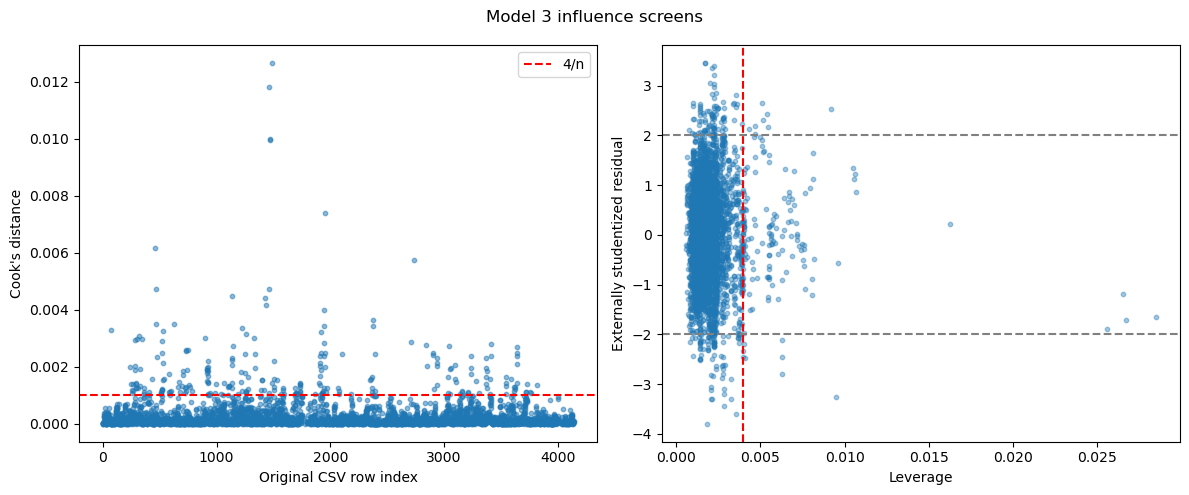

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(diagnostics.index, diagnostics["cooks_d"], s=10, alpha=0.5)
axes[0].axhline(cook_cutoff, color="red", linestyle="--", label="4/n")
axes[0].set_xlabel("Original CSV row index")
axes[0].set_ylabel("Cook's distance")
axes[0].legend()
axes[1].scatter(diagnostics["hat_diag"], diagnostics["studentized_residual"],
                s=10, alpha=0.4)
axes[1].axvline(leverage_cutoff, color="red", linestyle="--")
axes[1].axhline(2, color="grey", linestyle="--")
axes[1].axhline(-2, color="grey", linestyle="--")
axes[1].set_xlabel("Leverage")
axes[1].set_ylabel("Externally studentized residual")
fig.suptitle("Model 3 influence screens")
fig.tight_layout()
plt.show()

The screens flag **249/4,016** spaces by Cook's distance, **136/4,016** by leverage, and **189/4,016** by studentized residuals; these groups overlap. The highest Cook's distance is about **0.01266** for **CB3699, 601 MAIN ST**. Several high-leverage spaces share small downtown tracts, so I inspect identifiers and context rather than deleting records automatically.

DFBETAS is required by the assignment, but no DFBETAS example was found in the available lecture notebooks or course lab. I leave that specific requirement outstanding under the lecture-only restriction, rather than introduce an unreviewed technique.

## 7. Check sensitivity to Cook's-distance flags

I refit the same seven-variable specification after excluding only spaces above 4/n for Cook's distance. This is a sensitivity comparison, not a new cleaning rule, and I keep the 4,016-space fit as primary. Fit statistics across different samples do not establish that the screened sample is a better model.

In [15]:
keep = diagnostics["cooks_d"] <= cook_cutoff
model3_sensitivity = sm.OLS(y.loc[keep], X3.loc[keep]).fit()

sensitivity = pd.DataFrame({
    "Sample": ["Full sample (primary)", "Cook <= 4/n (sensitivity)"],
    "N": [int(model3.nobs), int(model3_sensitivity.nobs)],
    "Price coefficient": [model3.params["price_midpoint"],
                          model3_sensitivity.params["price_midpoint"]],
    "Price p-value": [model3.pvalues["price_midpoint"],
                      model3_sensitivity.pvalues["price_midpoint"]],
    "Adjusted R2": [model3.rsquared_adj, model3_sensitivity.rsquared_adj]
})
sensitivity.style.format({
    "Price coefficient": "{:.6f}", "Price p-value": "{:.3e}", "Adjusted R2": "{:.5f}"
})

,Sample,N,Price coefficient,Price p-value,Adjusted R2
0,Full sample (primary),4016,0.055633,4.731e-115,0.27235
1,Cook <= 4/n (sensitivity),3767,0.054769,1.393e-133,0.36202


In [16]:
sensitivity_coefficients = pd.DataFrame({
    "Full-sample coefficient": model3.params,
    "Sensitivity coefficient": model3_sensitivity.params,
    "Sensitivity p-value": model3_sensitivity.pvalues
})
sensitivity_coefficients.style.format({
    "Full-sample coefficient": "{:.6g}", "Sensitivity coefficient": "{:.6g}",
    "Sensitivity p-value": "{:.3e}"
})

,Full-sample coefficient,Sensitivity coefficient,Sensitivity p-value
const,0.456337,0.48932,2.835e-222
price_midpoint,0.0556328,0.054769,1.393e-133
time_limit_hours,0.00487929,0.0027943,2.905e-01
population_density,4.57052e-06,5.30055e-06,4.065e-132
nearby_restaurant_retail_count,-0.000321282,-0.000390916,2.212e-72
drive_alone_share,-0.198101,-0.247766,2.910e-39
transit_share,0.0196471,-0.03217,4.334e-01
RateType_TOD,0.0330042,0.0339612,7.397e-07


Excluding 249 flagged spaces leaves **3,767** observations. Price changes from **0.05563 to 0.05477**—about **5.56 to 5.48 percentage points per $1**—and remains positive with a small conventional p-value. The registration-count and drive-alone coefficients become more negative, while the uncertain transit estimate changes sign, so not every coefficient is equally stable.

Adjusted R² rises from 0.27235 to 0.36202, but the sample was selected using residual influence, which can mechanically improve fit. These p-values remain conventional and do not resolve the heteroskedasticity or dependence concerns. No observations are removed from the source file or the primary model.

## 8. Bootstrap the preferred specification

I follow the row-resampling examples in Lectures 1–2: sample with replacement, fit the same model, and record its coefficients for **1,000 replications**, with seed **90095**. I summarize all coefficients to match the assignment, then focus on price. This holds the selected specification fixed rather than rerunning variable selection in every draw.

In [17]:
np.random.seed(90095)
n_boot = 1000
bootstrap_coefficients = []

for i in range(n_boot):
    sample = data.sample(n=len(data), replace=True)
    X_boot = sm.add_constant(sample[predictors])
    bootstrap_model = sm.OLS(sample["occupancy_rate"], X_boot).fit()
    bootstrap_coefficients.append(bootstrap_model.params)

bootstrap = pd.DataFrame(bootstrap_coefficients)
print("Bootstrap replications:", len(bootstrap))
bootstrap_summary = pd.DataFrame({
    "Original OLS": model3.params,
    "Bootstrap mean": bootstrap.mean(),
    "Bootstrap SE": bootstrap.std(ddof=1),
    "Percentile 95% lower": bootstrap.quantile(0.025),
    "Percentile 95% upper": bootstrap.quantile(0.975)
})
bootstrap_summary.style.format("{:.6g}")

Bootstrap replications: 1000


,Original OLS,Bootstrap mean,Bootstrap SE,Percentile 95% lower,Percentile 95% upper
const,0.456337,0.456724,0.017315,0.422518,0.49125
price_midpoint,0.0556328,0.0554847,0.00237433,0.0509139,0.0601064
time_limit_hours,0.00487929,0.0049741,0.00314588,-0.000987099,0.0110299
population_density,4.57052e-06,4.58343e-06,2.35249e-07,4.11908e-06,5.07294e-06
nearby_restaurant_retail_count,-0.000321282,-0.000321162,2.41982e-05,-0.000371127,-0.000273167
drive_alone_share,-0.198101,-0.199397,0.0213658,-0.244678,-0.157657
transit_share,0.0196471,0.0202927,0.0445782,-0.0653932,0.102353
RateType_TOD,0.0330042,0.0327779,0.0086254,0.0160399,0.0487384


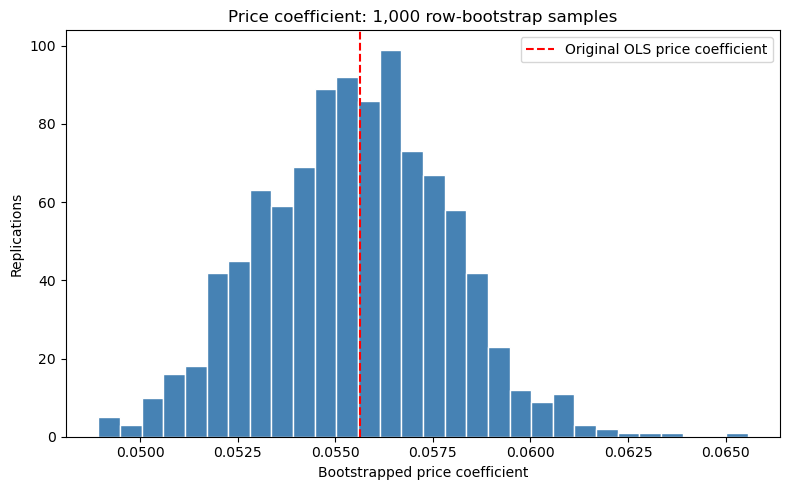

In [18]:
plt.figure(figsize=(8, 5))
plt.hist(bootstrap["price_midpoint"], bins=30, color="steelblue", edgecolor="white")
plt.axvline(model3.params["price_midpoint"], color="red", linestyle="--",
            label="Original OLS price coefficient")
plt.xlabel("Bootstrapped price coefficient")
plt.ylabel("Replications")
plt.title("Price coefficient: 1,000 row-bootstrap samples")
plt.legend()
plt.tight_layout()
plt.show()

The original price coefficient is **0.05563**; the bootstrap mean is **0.05548**, with bootstrap standard error **0.002374** and percentile interval **[0.05091, 0.06011]**. In percentage-point units per dollar, the interval is approximately **[5.09, 6.01]**, supporting stability of the positive association under this resampling scheme.

Ordinary row bootstrap treats spaces as independent even though the sample spans only 45 tracts and several predictors are shared within tracts. I found no tract-clustered inference example in the available lectures, so I document that dependence limitation rather than add a new estimator. The bootstrap does not fix endogeneity, mixed data vintages, or functional-form problems.

## 9. Reference the existing cross-validation results

Notebook 06, Section 8, already performs the required five-fold comparison with seed 10, identical folds across models, and training-only fits for held-out predictions. The assignment asks for five **or** ten folds, so I do not repeat that analysis or add ten folds unnecessarily. The following values are copied from its executed output, not reestimated here.

In [19]:
cv_reference = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Mean held-out RMSE (Notebook 06)": [0.17756, 0.16834, 0.16532]
})
cv_reference

,Model,Mean held-out RMSE (Notebook 06)
0,Model 1,0.17756
1,Model 2,0.16834
2,Model 3,0.16532


Model 3 has the lowest mean error, about **16.53 percentage points in root-mean-square terms**. Random-fold validation can place nearby spaces and the same tract in training and test data, and Notebook 05 used this sample for selection. It is a comparison of the fixed models for held-out spaces, not proof of performance in new neighborhoods or independent validation of the whole selection process.

## 10. Document the remaining sensor sensitivities

The current outcome retains intervals at most 24 hours and spaces with at least 25 transaction-active days. I inspect coverage in the existing 4,016-space sample below, without changing the outcome or applying an alternative sample rule. Active days are not necessarily fully monitored days.

In [20]:
print("Transaction-active days in the primary sample:")
print(parking.loc[data.index, "active_days"].value_counts().sort_index())

valid_month_fraction = parking.loc[data.index, "total_minutes"] / (31 * 24 * 60)
valid_month_fraction.describe()

Transaction-active days in the primary sample:
active_days
25     356
26    2032
27      19
28      45
29      89
30     184
31    1291
Name: count, dtype: int64


count    4016.000000
mean        0.822536
std         0.117815
min         0.315420
25%         0.741356
50%         0.775555
75%         0.966179
max         0.999898
Name: total_minutes, dtype: float64

Retained valid minutes average **82.25%** of August, with a median of **77.56%** and a minimum of **31.54%**. The earlier raw-data investigation also found Sunday-reporting differences. These observations explain why the researcher-selected interval and day rules deserve sensitivity checks; they do not themselves show which alternative rule is correct.

Only the original occupancy, inventory, and cross-section CSVs exist in `data/processed/`; no validated alternative-outcome files are available. A 28-day restriction can be applied to existing spaces, but the 20-day expansion and 12/48-hour interval outcomes require additional raw-data construction. I defer the joint comparison rather than present a partial rebuild as a completed robustness analysis.

### Processing needed before the sensor checks can proceed

The required input is `data/raw/ladot_occupancy/20261017T052111914317Z/Sensor Transactions_2025_08.csv`, containing **3,707,820 transactions**. I would parse the existing local timestamp format, sort within SpaceID, compute the next-record interval before excluding UNKNOWN states, and aggregate occupied/valid minutes separately under 12-, 24-, and 48-hour cutoffs. Raw active days would be counted before applying 20-, 25-, and 28-day restrictions.

The expanded samples would then need verified meter/predictor linkage; newly eligible spaces may lack the neighborhood predictors saved for the original sample. Comparisons should distinguish a common-space change in Y from a change in sample composition, and any new outputs must use separate paths. This raw-data rebuild requires approval under the task instructions, so it is **not implemented**, and Notebooks 01–06 and all existing datasets remain unchanged.

## 11. Summarize the diagnostics and remaining requirements

I combine the tests and robustness checks below, keeping screening rules distinct from decisions to change the data. A normality test that does not reject does not offset the variance and functional-form concerns. The price association is stable in the completed sensitivity checks, but its interpretation remains conditional and noncausal.

In [21]:
diagnostic_summary = pd.DataFrame([
    ["Residual plots", "Uneven spread; tract bands", "Inspect variance and mean specification", "Yes"],
    ["Jarque–Bera", f"p = {jb[1]:.3g}", "Do not reject normality at 5%", "Review with other assumptions"],
    ["Breusch–Pagan LM", f"p = {bp[1]:.3e}", "Reject constant variance", "Yes; HC1 comparison shown"],
    ["White LM", f"p = {white[1]:.3e}", "Reject constant variance", "Yes"],
    ["RESET", f"p = {float(reset.pvalue):.3e}", "Possible functional-form problem", "Yes"],
    ["Influence", f"{diagnostics['cook_flag'].sum()} Cook flags / {n}", "Screening flags, not confirmed errors", "Review identified spaces"],
    ["Cook sensitivity", f"Price = {model3_sensitivity.params['price_midpoint']:.5f}", "Positive price association remains", "Keep full sample primary"],
    ["Row bootstrap", f"{len(bootstrap):,} draws; price CI [{bootstrap_summary.loc['price_midpoint', 'Percentile 95% lower']:.5f}, {bootstrap_summary.loc['price_midpoint', 'Percentile 95% upper']:.5f}]", "Positive interval; independence assumed", "Dependence remains unresolved"],
    ["Five-fold CV", "Model 3 mean RMSE 0.16532 (Notebook 06)", "Best of the three fixed models", "New-neighborhood validity unresolved"],
    ["Sensor thresholds", "Not rebuilt", "Coverage rules may affect Y and sample", "Approval needed for raw-data rebuild"]
], columns=["Diagnostic", "Result", "Interpretation", "Further investigation"])
diagnostic_summary

,Diagnostic,Result,Interpretation,Further investigation
0,Residual plots,Uneven spread; tract bands,Inspect variance and mean specification,Yes
1,Jarque–Bera,p = 0.147,Do not reject normality at 5%,Review with other assumptions
2,Breusch–Pagan LM,p = 3.374e-41,Reject constant variance,Yes; HC1 comparison shown
3,White LM,p = 4.755e-63,Reject constant variance,Yes
4,RESET,p = 5.605e-28,Possible functional-form problem,Yes
5,Influence,249 Cook flags / 4016,"Screening flags, not confirmed errors",Review identified spaces
6,Cook sensitivity,Price = 0.05477,Positive price association remains,Keep full sample primary
7,Row bootstrap,"1,000 draws; price CI [0.05091, 0.06011]",Positive interval; independence assumed,Dependence remains unresolved
8,Five-fold CV,Model 3 mean RMSE 0.16532 (Notebook 06),Best of the three fixed models,New-neighborhood validity unresolved
9,Sensor thresholds,Not rebuilt,Coverage rules may affect Y and sample,Approval needed for raw-data rebuild


The full-sample price coefficient remains about **5.56 percentage points per $1**, and its row-bootstrap and HC1 intervals exclude zero. However, strong heteroskedasticity and RESET rejection mean I should not describe the original linear model as fully validated. HC1 addresses heteroskedastic uncertainty under independence, not shared-tract dependence, functional form, or demand-responsive pricing.

The October 2026 price proxy and business registrations also differ in timing and meaning from August 2025 occupancy. I keep the full 4,016-space Model 3 as the primary result and report the limitations before any final interpretation. No influential-observation screen becomes a permanent deletion rule, and no transformed specification is estimated here.

### Assignment compliance and lecture coverage

| Requirement | Current status |
|---|---|
| Reproduce the common sample and Models 1–3 | Completed here; matches Notebook 06 |
| Residual plots, scale-location plot, normal Q-Q plot and Jarque–Bera | Completed here using Lectures 1–2 |
| Breusch–Pagan, White and Ramsey RESET | Completed here using Lecture 2 |
| Heteroskedasticity-consistent uncertainty | HC1 completed using worked Lecture 2 code; HC3 is named but not demonstrated as a worked comparison |
| Cook's distance, leverage, studentized residuals and influence sensitivity | Completed here; 4/n is the requested project screen, and the leverage/studentized rules appear in Lecture 1 |
| DFBETAS | Required by the assignment but not found in the available lecture examples; still outstanding |
| Bootstrap coefficient estimates, 1,000 replications, compared with OLS | Completed here for all Model 3 coefficients, with price histogram and percentile interval |
| Five- or ten-fold validation and prediction accuracy | Already completed in Notebook 06; referenced here without repeating fits |
| Descriptive statistics, standard EDA plots and missingness | Completed in Notebook 04; predictor Q-Q/density plots, Pandas Profiling discussion and missingness sensitivity remain outstanding |
| Boruta, Mallows' Cp and VIF | Completed in Notebook 05 and left unchanged |
| Model comparison, coefficient interpretation and confidence intervals | Completed in Notebook 06, with additional uncertainty/sensitivity checks here |
| Assignment specification alignment | Model 2 still has four predictors versus the rubric's 2–3; Model 3's significance-based description needs justification, as noted in Notebook 06 |
| Sensor-cutoff/day/Sunday robustness | Still outstanding; no validated alternative files, and raw-data rebuild requires approval |
| Tract-clustered uncertainty | No worked example found in the available lectures; shared-neighborhood dependence remains a limitation |
| Economic literature, final policy/external-validity discussion, references and final presentation | Reserved for Notebook 08 / final report; no claim of complete submission compliance |
| PDF/HTML group submission with names and source code | Still outstanding |

The computational and statistical methods used here follow the reviewed lectures, apart from the Cook's 4/n screen explicitly supplied in the project instructions. I do not implement DFBETAS or clustered inference without course support. Notebook 08, earlier notebooks, and raw/processed files are not changed.